#  Ejercicio Practico de Detección de outliers
![logo Itq](img/ITQ.png)

** NOMBRE:** Willam Pincha

*10/11/2026*

**Link del Repositorio:**<a href="https://github.com/willy2026-code/fundamentoMachineLearningNocturno/blob/main/Prograna%202Estandarizacion.ipynb">Link Repositorio </a>

## 1. Importación de bibliotecas
- `pandas`: manejo de tablas.
- `numpy`: cálculos y posiciones.
- `scipy.stats`: percentiles.
- `scikit-learn`: detección de anomalías.
- `matplotlib`: gráficos.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.covariance import EllipticEnvelope
import matplotlib.pyplot as plt


## 2. Carga del conjunto de datos
El CSV tiene 200 filas y dos columnas (`a` y `b`). La carpeta `dataset` incluida en el ZIP evita tener que cambiar la ruta original.

In [2]:
# Carga de datos.
df = pd.read_csv("dataset/outliers.csv")
print(df)
df

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
195 -5.114441  0.646251
196  5.631630  0.277174
197  1.552784  2.348984
198 -0.545507  1.530697
199  1.011772  4.813896

[200 rows x 2 columns]


,a,b
0,0.149014,-0.041479
1,0.194307,0.456909
2,-0.070246,-0.070241
3,0.473764,0.230230
4,-0.140842,0.162768
...,...,...
195,-5.114441,0.646251
196,5.631630,0.277174
197,1.552784,2.348984
198,-0.545507,1.530697


## 3. Método EllipticEnvelope
Detecta observaciones alejadas de una región elíptica ajustada a los datos. `contamination=0.25` indica una proporción esperada del 25 % de anomalías. En la predicción, `-1` indica atípico y `1` indica normal.

In [3]:
# Entrenamos un objeto de tipo EllipticEnvelope
algorithm = EllipticEnvelope(support_fraction=None, contamination=0.25,
                             random_state=42)
outlier_method = algorithm.fit(df)

# Aplicamos el método de detección de outliers entrenado sobre nuestro dataset
df_outliers = outlier_method.predict(df)
print(df_outliers)

# Determinar la posición de los outliers
pos_outliers = np.where(df_outliers==-1)[0]
print('\nOutliers en la posición: \n', pos_outliers)

# Determinar el número de outliers
print('\nNúmero de outliers: \n', len(pos_outliers))

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]

Outliers en la posición: 
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185
 186 187 188 189 190 191 192 193 194 195 196 197 198 199]

Número de outliers: 
 50


### Función reutilizable
Permite aplicar un algoritmo de detección y recuperar etiquetas y posiciones atípicas.

In [4]:
# Definimos una función que, dado un determinado "df" y un "algorithm",
# devuelva la matriz y la posición de outliers
def find_outliers(df, algorithm):
    outlier_method = algorithm.fit(df)
    # Aplicamos el método de detección de outliers entrenado sobre nuestro dataset
    df_outliers = outlier_method.predict(df)
    print(df_outliers)
    # Determinamos la posición de los outliers
    pos_outliers=np.where(df_outliers==-1)[0]
    print('\nOutliers en la posición :\n', pos_outliers)
    # Determinamos el número de outliers
    print('\nNúmero de outliers: \n', len(pos_outliers))
    return df_outliers, pos_outliers

## 4. Otros métodos similares — IsolationForest
Este método aísla observaciones mediante divisiones aleatorias. Los métodos `OneClassSVM` y `LocalOutlierFactor` aparecen importados en el documento original como alternativas sin configurar (`??`), por eso no se ejecutan aquí.

In [5]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor

IF = IsolationForest(max_samples='auto', random_state=42)
OC_SVM = OneClassSVM(kernel="poly", degree=1, gamma="auto")
LOF = LocalOutlierFactor(n_neighbors=10, algorithm="auto", metric="euclidean")

df_outliers, pos_outliers = find_outliers(df, IF)
print(len(pos_outliers))

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1  1 -1]

Outliers en la posición :
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 165 166 167 168
 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186
 187 188 189 190 191 192 193 194 195 196 197 199]

Número de outliers: 
 48
48


### Primeras diez filas

In [6]:
df.head(10)

,a,b
0,0.149014,-0.041479
1,0.194307,0.456909
2,-0.070246,-0.070241
3,0.473764,0.230230
4,-0.140842,0.162768
5,-0.139025,-0.139719
6,0.072589,-0.573984
7,-0.517475,-0.168686
8,-0.303849,0.094274
9,-0.272407,-0.423691


## 5. Gráfico de la frontera de decisión
La zona central concentra observaciones habituales; las más alejadas pueden etiquetarse como atípicas. Los colores de fondo representan los valores de la función de decisión de IsolationForest. **Nota:** se ajustó la leyenda del PDF para que identifique correctamente ambas clases.

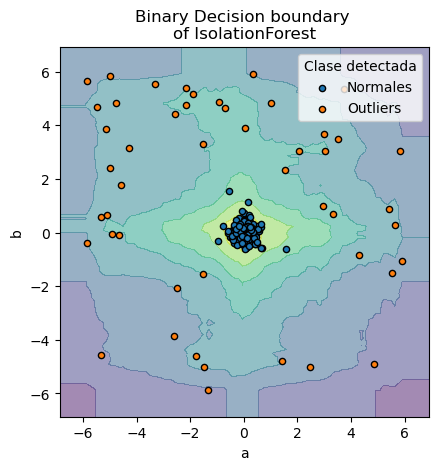

In [7]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

disp = DecisionBoundaryDisplay.from_estimator(
    IF,
    df,
    response_method="decision_function",
    alpha=0.5,
)
# Gráfico equivalente al original, con leyenda correspondiente a las etiquetas
normal = df_outliers == 1
anormal = df_outliers == -1
disp.ax_.scatter(df.loc[normal, 'a'], df.loc[normal, 'b'], s=20,
                 edgecolor="k", label="Normales")
disp.ax_.scatter(df.loc[anormal, 'a'], df.loc[anormal, 'b'], s=20,
                 edgecolor="k", label="Outliers")
disp.ax_.set_title("Binary Decision boundary \nof IsolationForest")
plt.axis("square")
plt.legend(title="Clase detectada")
plt.show()

## 6. Eliminación de outliers
Se conservan únicamente las filas clasificadas como normales (`1`) por IsolationForest. **Importante:** eliminar anomalías depende del objetivo del análisis; no siempre conviene hacerlo.

In [8]:
# Eliminamos los outliers
new_df = df[df_outliers==1]
print(new_df)

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
147  0.107105 -0.207873
148  0.269880  0.092190
149  0.243859  0.188889
164  1.582047 -0.618654
198 -0.545507  1.530697

[152 rows x 2 columns]


## 7. Box plot — método del rango intercuartílico
El rango intercuartílico (RIC) es `Q3 - Q1`. Los límites habituales son `Q1 - 1.5 × RIC` y `Q3 + 1.5 × RIC`. Este método se aplica primero a la columna `a`.

limite inferior:  -1.0853060827395105
limite superior:  1.0119554520872196
Posición de outliers:  [150 153 154 157 159 160 162 165 168 169 171 172 174 175 177 178 181 184
 185 186 187 190 191 192 193 195 151 152 155 156 161 163 164 166 167 173
 176 179 180 182 188 189 196 197]
Número de outliers:  44


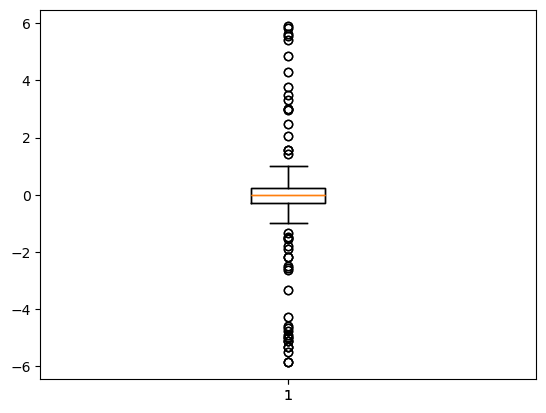

In [9]:
# Seleccionamos el atributo que vamos a medir
a = df['a']

# Seleccionamos los umbrales a partir de los cuales vamos a considerar outliers
Q1 = stats.scoreatpercentile(a, 25)
Q3 = stats.scoreatpercentile(a, 75)
RIC = Q3 - Q1
li = Q1 - 1.5*RIC #xmin
ls = Q3 + 1.5*RIC #xmax

# Observamos los límites inferior y superior
print('limite inferior: ', li)
print('limite superior: ', ls)

# Buscamos la posición de los outliers
pos_i = np.where(a<li)[0]
pos_s = np.where(a>ls)[0]
pos_outliers = np.concatenate((pos_i, pos_s))
print('Posición de outliers: ', pos_outliers)
print('Número de outliers: ', len(pos_outliers))

# Dibujamos el diagrama de caja y bigotes
prop = plt.boxplot(a)
plt.boxplot(a)
plt.show()

## 8. Función para todas las columnas
En el PDF, `find_limits_BP` estaba incompleta (`# ???`) y ocasionaba `NameError`. Aquí se completa su cuerpo para que el último bloque funcione, sin cambiar la finalidad del ejercicio.

In [23]:
# Definir una función que, dada una columna de un dataframe, devuelva la
# posición de los outliers según el método box plot
def find_limits_BP(variable):
    Q1 = stats.scoreatpercentile(variable, 25)
    Q3 = stats.scoreatpercentile(variable, 75)
    RIC = Q3 - Q1
    li = Q1 - 1.5*RIC
    ls = Q3 + 1.5*RIC
    pos_i = np.where(variable<li)[0]
    pos_s = np.where(variable>ls)[0]
    pos_outliers = np.concatenate((pos_i, pos_s))
    return pos_outliers

In [24]:
# Creamos un bucle for que estime los valores outliers de cada atributo
headers = df.columns # nombre de los atributos del CSV
pos_outliers = []
for i in range(len(headers)):
    variable = df[headers[i]] # Atributo 'x'
    pos_out = np.expand_dims(find_limits_BP(variable), axis=1)
    pos_outliers.append(pos_out) # Lo añadimos en una lista

# Concatenamos todas las posiciones de outliers
po = np.vstack(pos_outliers)

# Vemos las posiciones de todos los outliers
pos_out = np.unique(po)
print('Posiciones de outliers: ', pos_out)

# Observamos el número de outliers
print('Numero de outliers: ', len(pos_out))

Posiciones de outliers:  [104 150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166
 167 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184
 185 186 187 188 189 190 191 192 193 194 195 196 197 198 199]
Numero de outliers:  51


## Interpretación final
- **EllipticEnvelope:** utiliza una distribución elíptica robusta; con contaminación de 0.25 detecta aproximadamente 50 filas en este ejercicio.
- **IsolationForest:** identifica casos que pueden aislarse rápidamente; sus resultados no tienen por qué coincidir exactamente con los de EllipticEnvelope.
- **Box plot:** detecta valores alejados de los cuartiles en cada variable, sin considerar conjuntamente las dos variables.

